# Studio della magnetizzazione di una catena di Ising

*Prima di iniziare: esegui la seguenti celle di codice! In questo modo potrai utilizzare la libreria Qiskit, assieme ad una funzione che abbiamo creato appositamente per permettervi di testare velocemente i vostri circuiti!*

In [ ]:
%pip install -q qiskit==2.5.2
%pip install -q qiskit-algorithms
%pip install -q pylatexenc
%pip install matplotlib

# Qiskit Fall Fest 2026 - Transizione di Fase Quantistica nel Modello di Ising 1D

<div>
In questo notebook viene esplorato il Modello di Ising quantistico monodimensionale e analizzata la sua transizione di fase indotta da un campo trasverso. Il problema del ground-state viene affrontato utilizzando tecniche di diagonalizzazione classica esatta tramite <code>NumPyMinimumEigensolver</code>, al fine di studiare il comportamento della magnetizzazione e l'effetto della rottura di simmetria a taglia finita. Per approfondire la teoria e gli algoritmi quantistici correlati, è possibile consultare i seguenti materiali:

- <a href="https://quantum.cloud.ibm.com/learning/en/courses/quantum-diagonalization-algorithms/introduction">Quantum diagonalization algorithms</a>
- <a href="https://learning.quantum.ibm.com/tutorial/simulate-the-dynamics-of-a-spin-1-2-system-on-a-kagome-lattice">Simulate the dynamics of a spin-1/2 system on a lattice</a>
</div>

## Obiettivi di apprendimento:
- Comprendere la formulazione dell'Hamiltoniana del Modello di Ising quantistico tramite operatori di Pauli.
- Analizzare l'effetto del campo trasverso sulla Sfera di Bloch e il passaggio dalla base $Z$ alla base $X$.
- Comprendere il ruolo del microcampo longitudinale ($\varepsilon$) nella rottura esplicita della simmetria per sistemi a taglia finita.
- Saper interpretare i risultati della diagonalizzazione esatta per tracciare e comprendere la transizione di fase quantistica.

## 0. Introduzione

L'indagine delle transizioni di fase è uno dei pilastri della fisica della materia condensata. Mentre le transizioni classiche (come lo scioglimento del ghiaccio) sono guidate dall'agitazione termica, le transizioni di fase quantistiche avvengono allo zero assoluto ($T=0$) e sono guidate unicamente dalle fluttuazioni quantistiche indotte dal Principio di Indeterminazione di Heisenberg.

Per studiare questi fenomeni, formuliamo il problema matematicamente scrivendo l'Hamiltoniana del sistema, una matrice che racchiude tutte le interazioni in gioco. Diagonalizzare questa matrice significa disaccoppiare il sistema per estrarne gli autovalori (i livelli di energia) e gli autovettori (gli stati fisici). In questo notebook, ci concentreremo sulla ricerca esatta del *ground-state* (lo stato di minima energia) per un materiale magnetico unidimensionale. Risolvere questo problema ci permette di calcolare il parametro d'ordine macroscopico, la magnetizzazione, e di osservare come il sistema "scelga" spontaneamente il suo stato fondamentale al variare delle forze esterne.

## 1. Costruire Operatori Sparsi con Qiskit

Prima di definire la complessa struttura a molti corpi del Modello di Ising, è essenziale padroneggiare gli strumenti software necessari per mappare la fisica sul computer.

In questa sezione esploreremo i fondamenti della costruzione degli operatori quantistici in Qiskit. Impareremo a tradurre la matematica degli spin in codice utilizzando le stringhe di Pauli (`I`, `X`, `Y`, `Z`) e la classe `SparsePauliOp`. Quest'ultima ci permetterà di istanziare matrici sparse in modo altamente efficiente, gettando le basi per costruire Hamiltoniane e osservabili fisiche.

**Cosa vedremo in questa sezione:**
* **Stringhe di Pauli:** Come rappresentare operatori locali e globali su $N$ spin.
* **`SparsePauliOp`:** Come associare i coefficienti fisici (come $J$ o $h$) alle stringhe operative.
* **Operatori di Base:** Esempi pratici di costruzione prima di scalare il modello a $N$ particelle.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp, Statevector, partial_trace
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit.visualization import plot_bloch_multivector
from IPython.display import display

### Esempio 1: L'Operatore Identità

Iniziamo costruendo una stringa di Pauli "neutra" per un sistema di 5 particelle. L'operatore Identità (`I`) è l'equivalente quantistico del non fare nulla: lascia inalterato lo stato della particella. Inserendo 5 operatori `I` nella nostra stringa, creiamo un operatore globale che agisce su tutta la catena senza perturbarla.

In [ ]:
paulis = []
coeffs = []

N =5
z_string = ['I']*N

print(z_string)

['I', 'I', 'I', 'I', 'I']


Adesso applichiamo l'operatore (`Z`) al secondo spin e inseriamo la stringa all'interno della lista (`paulis`) definita in precedenza. Per associare il coefficiente (`-J`) alla configurazione appena creata lo inseriamo all'interno della lista ausiliaria (`coeffs`). ("N.B. Non dimenticarti del segno meno quando effettui l'inserimento del coefficiente")

In [ ]:
J = 1
z_string[1] = 'Z'

paulis.append("".join(z_string))
coeffs.append(-J)

print(z_string)

['I', 'Z', 'I', 'I', 'I']


Continuaiamo ripristinando lo stato neutro reinserendo (`I`) nella posizione originale, dopodichè applichiamo (`X`) al terzo spin e inseriamo la configurazione come fatto in precedenza associando questa volta il coefficiente (`h`).("N.B. Non dimenticarti del segno meno quando effettui l'inserimento del coefficiente")

In [ ]:
z_string[1] = 'I'
z_string[2] = 'X'
h = 0.5

paulis.append("".join(z_string))
coeffs.append(-h)

print(paulis)
print(coeffs)

['IZIII', 'IIXII']
[-1, -0.5]


Adesso siamo pronti per costruire l'operatore sparso: inserisci le due liste (`paulis`) e (`coeffs`) nei parametri della funzione (`SparsePauliOp`) e osservane la composizione

In [ ]:
OP = SparsePauliOp(paulis, coeffs)
print(OP)

SparsePauliOp(['IZIII', 'IIXII'],
              coeffs=[-1. +0.j, -0.5+0.j])


## 2. Costruire una catena di Ising per un singolo spin ($N=1$)

Adesso che abbiamo imparato a manipolare e costruire gli operatori sparsi, facciamo il primo passo verso la simulazione fisica costruendo l'Hamiltoniana per il caso più semplice possibile: una catena formata da un singolo spin.

Sebbene un singolo spin non possa interagire con i propri vicini (l'interazione $J$ sarà assente), questo caso studio è fondamentale per validare la nostra pipeline di calcolo prima di scalare il sistema a molti corpi.

**Obiettivi di questa sezione:**
* **Costruzione dell'Hamiltoniana:** Utilizzeremo le stringhe di Pauli e i coefficienti fisici (il campo trasverso $h$ e il microcampo longitudinale $\varepsilon$) per mappare l'energia del sistema in un operatore hermitiano.
* **Diagonalizzazione:** Invocheremo il `NumPyMinimumEigensolver` per estrarre analiticamente lo stato di minima energia (il *Ground State*).
* **L'Osservabile Magnetizzazione:** Definiremo matematicamente l'operatore di Magnetizzazione Media ($M_z$) e ne calcoleremo il valore di aspettazione sul *Ground State* appena trovato.

Inizia costruendo le due stringhe, associando (`h`) alla stringa contenente solo (`X`) e ($\varepsilon$) alla stringa contenente (`Z`)

In [ ]:
paulis = []
coeffs = []
N = 1
h = 0
eps=1e-5

z_string = ['X']
paulis.append("".join(z_string))
coeffs.append(-h)

z_string = ['Z']
paulis.append("".join(z_string))
coeffs.append(-eps)

H1 = SparsePauliOp(paulis, coeffs)
print(H1)


SparsePauliOp(['X', 'Z'],
              coeffs=[ 0.e+00+0.j, -1.e-05+0.j])


Invoca la funzione (`NumPyMinimumEigensolver()`) per ottenere il (`solver`). Successivamente invoca la funzione del solve (`.compute_minimum_eigenvalue('Hamiltoniana')`) per diagonalizzare l'Hamiltoniana e calcolare l'energia minima. Infine utilizza l'attributo (`.eigenstate`) del risultato per ottenere il (`ground_state`)

In [ ]:
solver = NumPyMinimumEigensolver()

result = solver.compute_minimum_eigenvalue(H1)
ground_state = result.eigenstate
print(ground_state)

Statevector([1.+0.j, 0.+0.j],
            dims=(2,))


Per calcolare la Magnetizzazione costruiamo l'operatore associato applicando l'operatore (`Z`) con coefficiente $\frac{1}{N}$.

In [ ]:
paulis = []
coeffs = []

z_string = ['Z']
paulis.append("".join(z_string))
coeffs.append(1.0/N)

M1 = SparsePauliOp(paulis, coeffs)
print(M1)


SparsePauliOp(['Z'],
              coeffs=[1.+0.j])


Adesso siamo pronti per calcolare la magnetizzazione sul nostro Spin! Utilizza il la funzione (`expectation_value("OP_magnetizzazione")`) per calcolarne la media e visualizza il risultato

In [ ]:
m_z_val = ground_state.expectation_value(M1)
print(f"Campo h: {h} -> Magnetizzazione: {m_z_val.real}")

Campo h: 0 -> Magnetizzazione: 1.0


### Alcune Considerazioni
Il calcolo di $\frac{1}{N}$ e del valore atteso sono banali per N = 1, tuttavia effettuare questi passaggi ci è utile per poter generalizzare più avanti  

## 3. Costruire una catena di Ising per due spin ($N=2$)

Il prossimo passo è scalare il sistema a due particelle. Questo passaggio è critico perché, per la prima volta, entra in gioco il termine di interazione (l'accoppiamento $J$) all'interno dell'Hamiltoniana. Il nostro singolo spin non è più isolato, ma "sente" la presenza del suo vicino, creando una competizione diretta tra il campo esterno e la tendenza degli spin ad allinearsi.

Inoltre, sfrutteremo questo sistema ristretto per visualizzare dinamicamente lo stato quantistico sulla Sfera di Bloch, osservando visivamente la transizione di fase indotta dall'aumento del campo trasverso $h$.

**Obiettivi di questa sezione:**
* **Termine di accoppiamento ($J$):** Introdurremo gli operatori bi-locali ($ZZ$) per mappare l'interazione ferromagnetica o antiferromagnetica tra i due spin.
* **Utilizzo dei cicli per la costruzione delle stringhe:** Abbandoneremo la scrittura manuale delle stringhe di Pauli implementando l'uso dei cicli `for` in Python, rendendo il nostro codice in grado di scalare automaticamente a $N$ particelle.
* **Osservazione della transizione sulla Sfera di Bloch:** Utilizzeremo l'operazione di traccia parziale per isolare un singolo spin e osservare il vettore di stato cadere dall'asse $Z$ (dominio dell'interazione spaziale) verso l'asse $X$ (dominio del campo trasverso) all'aumentare di $h$.

Costruisci l'Hamiltoniana inserendo gli operatori (`ZZ`) e utilizzando i cicli for per generalizzare la costruzione

In [ ]:
paulis = []
coeffs = []
N = 2
J = 1
h = 0
eps=1e-5

for i in range(N-1):
    z_string = ['I']*N
    z_string[i] = 'Z'
    z_string[i+1] = 'Z'
    paulis.append("".join(z_string))
    coeffs.append(-J)

for i in range(N):
    z_string = ['I']*N
    z_string[i] = 'X'
    paulis.append("".join(z_string))
    coeffs.append(-h)

for i in range(N):
    z_string = ['I']*N
    z_string[i] = 'Z'
    paulis.append("".join(z_string))
    coeffs.append(-eps)

H2 = SparsePauliOp(paulis, coeffs)


Calcola lo stato Ground come fatto in precedenza

In [ ]:
solver = NumPyMinimumEigensolver()

result = solver.compute_minimum_eigenvalue(H2)
ground_state = result.eigenstate
print(ground_state)

Statevector([1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2))


Costruisci l'operatore magnetizzazione utilizzando il ciclo for sugli N elementi

In [ ]:
paulis = []
coeffs = []


for i in range(N):
    z_string = ['I']*N
    z_string[i] = 'Z'
    paulis.append("".join(z_string))
    coeffs.append(1.0/N)

M2 = SparsePauliOp(paulis, coeffs)


m_z_val = ground_state.expectation_value(M2)
print(f"Campo h: {h} -> Magnetizzazione: {m_z_val.real}")

Campo h: 0 -> Magnetizzazione: 1.0


Esegui la prossima casella per visualizzare lo stato del primo spin nella sfera di bloch con (`h = 0`)

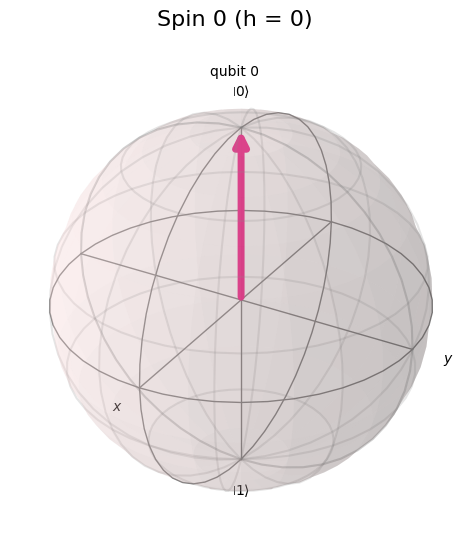

In [ ]:
target_spin = 0

N = ground_state.num_qubits
qubits_to_trace_out = [i for i in range(N) if i != target_spin]

if len(qubits_to_trace_out) > 0:
    reduced_density_matrix = partial_trace(ground_state, qubits_to_trace_out)
else:
    reduced_density_matrix = ground_state

fig = plot_bloch_multivector(reduced_density_matrix, title=f"Spin {target_spin} (h = {h})")
display(fig)

Replica i passaggi precedenti ma utilizzando (`h = 1`)

In [ ]:
paulis = []
coeffs = []
N = 2
J = 1
h = 1
eps=1e-5
for i in range(N-1):
    z_string = ['I']*N
    z_string[i] = 'Z'
    z_string[i+1] = 'Z'
    paulis.append("".join(z_string))
    coeffs.append(-J)

for i in range(N):
    z_string = ['I']*N
    z_string[i] = 'X'
    paulis.append("".join(z_string))
    coeffs.append(-h)

for i in range(N):
    z_string = ['I']*N
    z_string[i] = 'Z'
    paulis.append("".join(z_string))
    coeffs.append(-eps)

H2 = SparsePauliOp(paulis, coeffs)

solver = NumPyMinimumEigensolver()

result = solver.compute_minimum_eigenvalue(H2)
ground_state = result.eigenstate
print(ground_state)


print(f"Campo h: {h} -> Magnetizzazione: {m_z_val.real}")

Statevector([0.30516336-0.51835358j, 0.18859828-0.32035495j,
             0.18859828-0.32035495j, 0.30515349-0.5183368j ],
            dims=(2, 2))
Campo h: 1 -> Magnetizzazione: 1.0


Eseguendo la prossima cella potrai osservare che il vettore adesso si trova lungo l'asse `X`

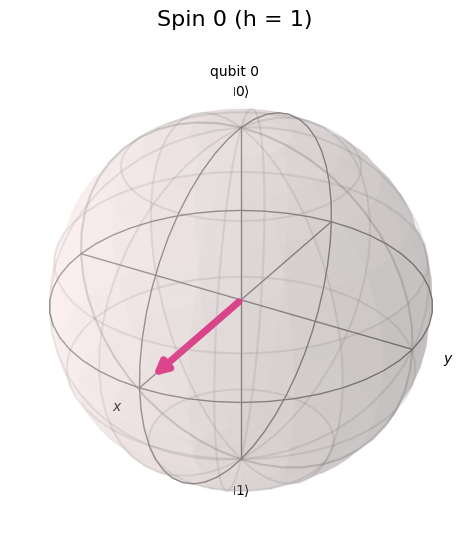

In [ ]:
target_spin = 0

N = ground_state.num_qubits
qubits_to_trace_out = [i for i in range(N) if i != target_spin]

if len(qubits_to_trace_out) > 0:
    reduced_density_matrix = partial_trace(ground_state, qubits_to_trace_out)
else:
    reduced_density_matrix = ground_state

fig = plot_bloch_multivector(reduced_density_matrix, title=f"Spin {target_spin} (h = {h})")
display(fig)

## 4. Costruire una catena di Ising generica per $N$ spin

Dopo aver validato la fisica sui sistemi ristretti, l'ultimo step computazionale è incapsulare tutta la logica all'interno di una funzione generale. Questo ci permetterà di istanziare un'Hamiltoniana per un numero arbitrario $N$ di spin, passando dalla teoria di pochi corpi alla simulazione di una vera catena magnetica.

In questa fase introdurremo anche la possibilità di gestire le *condizioni al contorno*, scegliendo se studiare una catena aperta (i due spin alle estremità non si parlano) o una catena chiusa con termini di raccordo (l'ultimo spin interagisce con il primo, formando un anello perfetto).

**Obiettivi di questa sezione:**
* **Generalizzazione dell'Hamiltoniana:** Scriveremo una funzione robusta capace di scalare le stringhe di Pauli su $N$ siti, includendo facoltativamente i termini di interazione periodica ai bordi.
* **Studio della Magnetizzazione:** Eseguiremo il solver su un intervallo continuo del campo trasverso ($h \in [0,1.5]$) per calcolare la magnetizzazione del Ground State e tracciare finalmente il grafico della transizione di fase.
* **Esplorazione e Sperimentazione:** Avremo a disposizione un laboratorio virtuale completo per variare le dimensioni del sistema, testare l'effetto delle condizioni al contorno, o variare l'intensità del microcampo $\varepsilon$ per osservare la reazione del parametro d'ordine macroscopico.

Iniziamo definendo la funzione per la costruzione dell'Hamiltoniana. Costruisci le stringhe di Pauli come fatto in precedenza introducendo le condizioni periodiche tramite il flag (`period`): per implementarle è sufficiente costruire un'ulteriore stringa inserendo (`Z`) nella prima e nell'ultima posizione

In [ ]:
def ising_hamiltonian(N, h, J=1.0, period=False, eps=1e-5):
    paulis = []
    coeffs = []


    # Termine di Interazione:
    for i in range(N - 1):
        z_string = ['I']*N
        z_string[i] = 'Z'
        z_string[i+1] = 'Z'
        paulis.append("".join(z_string))
        coeffs.append(-J)

    # Chiusura ad anello:
    if period:
        z_string = ['I']*N
        z_string[0] = 'Z'
        z_string[-1] = 'Z'
        paulis.append("".join(z_string))
        coeffs.append(-J)

    # Termine del Campo Trasverso:
    for i in range(N):
        x_string = ['I']*N
        x_string[i] = 'X'
        paulis.append("".join(x_string))
        coeffs.append(-h)

    # Microcampo
    for i in range(N):
        z_string = ['I']*N
        z_string[i] = 'Z'
        paulis.append("".join(z_string))
        coeffs.append(-eps)


    return SparsePauliOp(paulis, coeffs)

Definiamo la funzione per costruire l'operatore Magnetizzazione su catene di dimensione arbitraria N in maniera analoga a quanto fatto nelle celle precedenti

In [ ]:
def magnetization_op(N):
    paulis = []
    coeffs = []

    for i in range(N):
        z_string = ['I']*N
        z_string[i] = 'Z'
        paulis.append("".join(z_string))
        coeffs.append(1.0 / N)


    return SparsePauliOp(paulis, coeffs)

Richiamiamo le funzioni facendo variare (`h`) tra 0 e 1.5 e calcoliamo la magnetizzazione sugli stati ground inserendo i valori nella lista (`magnetizations`).
È consigliato l'utilizzo di `N = 8` o inferiore. ("N.B. Oltre N = 10 il programma potrebbe essere troppo lento")

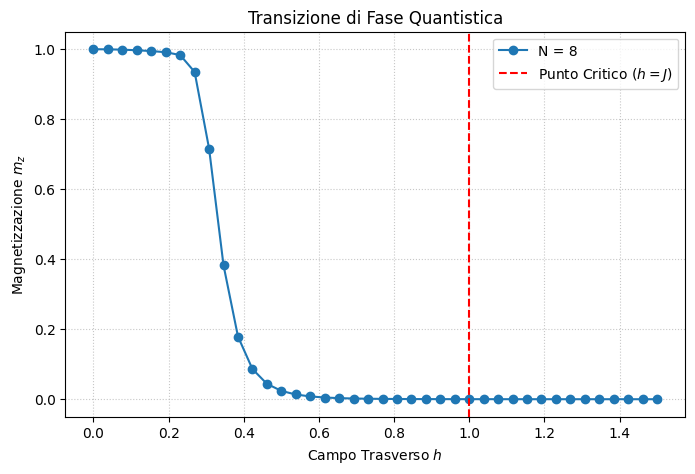

In [ ]:
N = 8
J = 1
h_values = np.linspace(0, 1.5, 40)
magnetizations = []

solver = NumPyMinimumEigensolver()
Mz_op = magnetization_op(N)

for h in h_values:
    H = ising_hamiltonian(N, h, J=J)

    # Trova il ground state dell'Hamiltoniana
    result = solver.compute_minimum_eigenvalue(H)
    ground_state = result.eigenstate

    # Calcola il valore atteso della Magnetizzazione
    m_z_val = ground_state.expectation_value(Mz_op)

    magnetizations.append(m_z_val.real)

# Plot della Transizione di Fase Quantistica
plt.figure(figsize=(8, 5))
plt.plot(h_values, magnetizations, 'o-', color='#1f77b4', label=f'N = {N}')
plt.axvline(x=1, color='r', linestyle='--', label='Punto Critico ($h=J$)')
plt.xlabel('Campo Trasverso $h$')
plt.ylabel('Magnetizzazione $m_z$')
plt.title('Transizione di Fase Quantistica')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

Adesso testiamo la magnetizzazione su una catena di dimensione inferiore e confrontiamola con i risultati precedenti

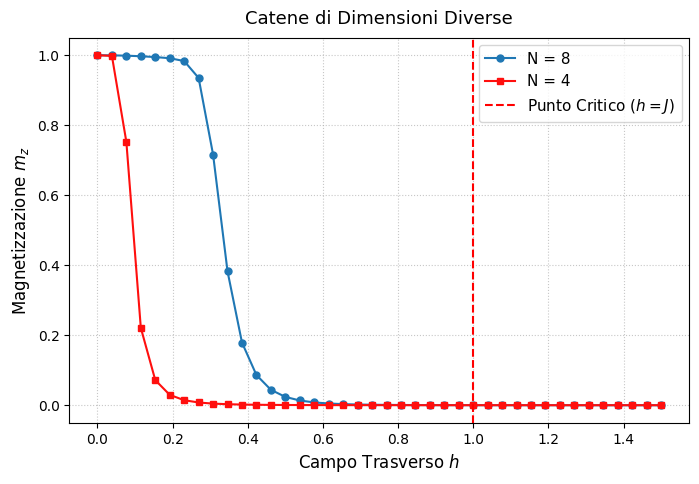

In [ ]:
magnetizations_small = []
N_SMALL = 4
Mz_op_small = magnetization_op(N_SMALL)

for h in h_values:
    H_small = ising_hamiltonian(N_SMALL, h, J=J)

    result = solver.compute_minimum_eigenvalue(H_small)
    ground_state = result.eigenstate

    m_z_val = ground_state.expectation_value(Mz_op_small)
    magnetizations_small.append(np.abs(m_z_val.real))


plt.figure(figsize=(8, 5))
plt.plot(h_values, magnetizations, 'o-', color='#1f77b4', markersize=5, label=f'N = {N}')
plt.plot(h_values, magnetizations_small, 's-', color='#ff0f0e', markersize=5, label=f'N = {N_SMALL}')

# Formattazione
plt.axvline(x=1, color='r', linestyle='--', linewidth=1.5, label='Punto Critico ($h=J$)')
plt.xlabel('Campo Trasverso $h$', fontsize=12)
plt.ylabel('Magnetizzazione $m_z$', fontsize=12)
plt.title('Catene di Dimensioni Diverse', fontsize=13, pad=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.show()

Effettuiamo un ulteriore confronto testando una catena con `J = 0.5`. Ci aspettiamo che la transizione avvenga più velocemente

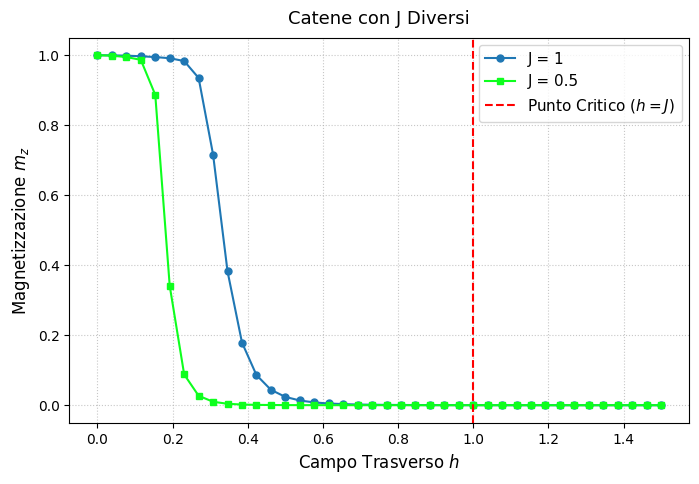

In [ ]:
magnetizations_Jsmall = []
J_SMALL = 0.5

for h in h_values:
    H = ising_hamiltonian(N, h, J=J_SMALL)

    result = solver.compute_minimum_eigenvalue(H)
    ground_state = result.eigenstate

    m_z_val = ground_state.expectation_value(Mz_op)
    magnetizations_Jsmall.append(np.abs(m_z_val.real))


plt.figure(figsize=(8, 5))
plt.plot(h_values, magnetizations, 'o-', color='#1f77b4', markersize=5, label=f'J = {J}')
plt.plot(h_values, magnetizations_Jsmall, 's-', color="#0eff1e", markersize=5, label=f'J = {J_SMALL}')

# Formattazione
plt.axvline(x=1, color='r', linestyle='--', linewidth=1.5, label='Punto Critico ($h=J$)')
plt.xlabel('Campo Trasverso $h$', fontsize=12)
plt.ylabel('Magnetizzazione $m_z$', fontsize=12)
plt.title('Catene con J Diversi', fontsize=13, pad=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.show()

Come ultimo test vediamo come l'utilizzo delle condizioni periodiche modifichi l'andamento la transizione. Esegui la funzione per la costruzione dell'Hamiltoniana con il flag (`period = True`)

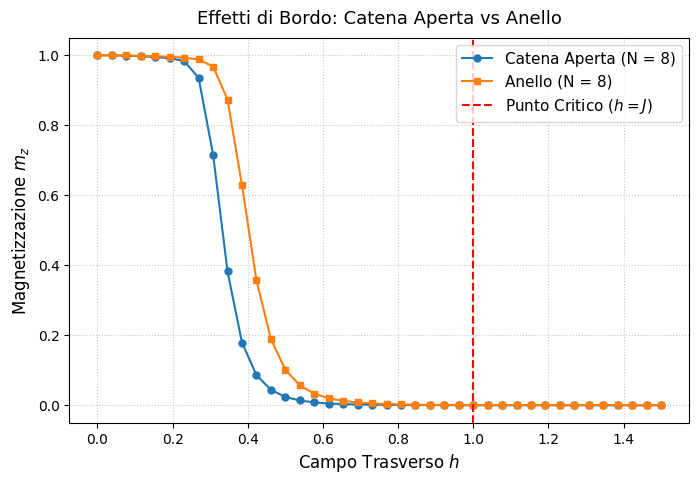

In [ ]:
magnetizations_ring = []

for h in h_values:
    # Impostiamo period=True per l'anello
    H_ring = ising_hamiltonian(N, h, J=J, period=True)

    result = solver.compute_minimum_eigenvalue(H_ring)
    ground_state = result.eigenstate

    m_z_val = ground_state.expectation_value(Mz_op)
    magnetizations_ring.append(np.abs(m_z_val.real))


plt.figure(figsize=(8, 5))
plt.plot(h_values, magnetizations, 'o-', color='#1f77b4', markersize=5, label=f'Catena Aperta (N = {N})')
plt.plot(h_values, magnetizations_ring, 's-', color='#ff7f0e', markersize=5, label=f'Anello (N = {N})')

# Formattazione
plt.axvline(x=1, color='r', linestyle='--', linewidth=1.5, label='Punto Critico ($h=J$)')
plt.xlabel('Campo Trasverso $h$', fontsize=12)
plt.ylabel('Magnetizzazione $m_z$', fontsize=12)
plt.title('Effetti di Bordo: Catena Aperta vs Anello', fontsize=13, pad=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.show()